# Entrenamiento del modelo de abandono

## 1. Objetivo del proyecto

Se construye un árbol de decisión para predecir si un cliente abandonará el servicio (Churn). El notebook se ejecuta desde la raíz del proyecto con el entorno Python mlops y guarda el pipeline en models/modelo.pkl.

## 2. Importación de librerías

Se importan las herramientas para preparar los datos, entrenar el modelo, evaluarlo y guardarlo.

In [1]:
from pathlib import Path

import joblib
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

## 3. Carga de datos

Se carga data/clientes.csv y se muestran los primeros registros para conocer sus columnas.

In [2]:
datos = pd.read_csv(Path("../data/clientes.csv"))
display(datos.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 4. Exploración inicial

Se revisan las dimensiones, los tipos de datos, los valores faltantes y la distribución de Churn. Los espacios de TotalCharges se detectan en la limpieza siguiente.

In [3]:
print("Dimensiones:", datos.shape)
display(datos.dtypes.to_frame("Tipo de dato"))
display(datos.isna().sum().to_frame("Valores faltantes"))
display(datos["Churn"].value_counts(dropna=False).to_frame("Clientes"))

Dimensiones: (7043, 21)


,Tipo de dato
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


,Valores faltantes
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


,Clientes
Churn,
No,5174
Yes,1869


## 5. Limpieza de datos

Se convierte TotalCharges a número; los espacios se transforman en valores faltantes que el pipeline imputará. Se elimina customerID porque solo identifica clientes.

In [4]:
datos["TotalCharges"] = pd.to_numeric(datos["TotalCharges"], errors="coerce")
datos = datos.drop(columns=["customerID"])
print("TotalCharges faltantes:", datos["TotalCharges"].isna().sum())

TotalCharges faltantes: 11


## 6. Variables y objetivo

Se separan las variables predictoras de Churn. La clase Yes se codifica como 1 y No como 0.

In [5]:
variables = datos.drop(columns=["Churn"])
objetivo = datos["Churn"].map({"No": 0, "Yes": 1})

## 7. División de entrenamiento y prueba

Se reserva el 20 % de los registros para evaluar el modelo. La estratificación conserva la proporción de ambas clases.

In [6]:
variables_entrenamiento, variables_prueba, objetivo_entrenamiento, objetivo_prueba = train_test_split(
    variables, objetivo, test_size=0.2, stratify=objetivo, random_state=42
)

## 8. Pipeline de preprocesamiento y modelo

Se convierten las columnas numéricas y se imputan sus valores faltantes con la mediana. Las columnas categóricas se imputan con el valor más frecuente y se codifican con OneHotEncoder. Toda la preparación queda dentro del pipeline guardado para aplicarla también durante la inferencia.

In [7]:
columnas_numericas = variables.select_dtypes(include="number").columns.tolist()
columnas_categoricas = variables.select_dtypes(include="object").columns.tolist()

preparacion_numerica = Pipeline([
    ("convertir_numeros", FunctionTransformer(
        pd.DataFrame.apply, kw_args={"func": pd.to_numeric, "errors": "coerce"}
    )),
    ("imputar", SimpleImputer(strategy="median")),
])
preparacion_categorica = Pipeline([
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("codificar", OneHotEncoder(handle_unknown="ignore")),
])
preprocesamiento = ColumnTransformer([
    ("numericas", preparacion_numerica, columnas_numericas),
    ("categoricas", preparacion_categorica, columnas_categoricas),
])
pipeline = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("modelo", DecisionTreeClassifier(max_depth=5, random_state=42)),
])

## 9. Entrenamiento

Se ajustan el preprocesamiento y el árbol de decisión únicamente con los datos de entrenamiento.

In [8]:
pipeline.fit(variables_entrenamiento, objetivo_entrenamiento)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specify

## 10. Evaluación

Se calculan Accuracy, Precision, Recall y F1 sobre los datos de prueba. La matriz de confusión muestra aciertos y errores para las clases No y Yes.

In [9]:
predicciones = pipeline.predict(variables_prueba)
metricas = {
    "Accuracy": accuracy_score(objetivo_prueba, predicciones),
    "Precision": precision_score(objetivo_prueba, predicciones, zero_division=0),
    "Recall": recall_score(objetivo_prueba, predicciones, zero_division=0),
    "F1": f1_score(objetivo_prueba, predicciones, zero_division=0),
}
display(pd.Series(metricas, name="Resultado").to_frame())
display(pd.DataFrame(
    confusion_matrix(objetivo_prueba, predicciones, labels=[0, 1]),
    index=["Real: No", "Real: Yes"],
    columns=["Predicho: No", "Predicho: Yes"],
))

,Resultado
Accuracy,0.798439
Precision,0.634731
Recall,0.566845
F1,0.598870


,Predicho: No,Predicho: Yes
Real: No,913,122
Real: Yes,162,212


## 11. Guardado del pipeline

Se guarda el pipeline completo en models/modelo.pkl. Este paso se ejecuta después del entrenamiento y permite reutilizar el mismo preprocesamiento en la aplicación.

In [10]:
Path("models").mkdir(exist_ok=True)
joblib.dump(pipeline, Path("../models/modelo.pkl"))

['..\\models\\modelo.pkl']

## Interpretación del modelo

Se visualiza el árbol entrenado y se revisa qué variables influyen más en sus decisiones.

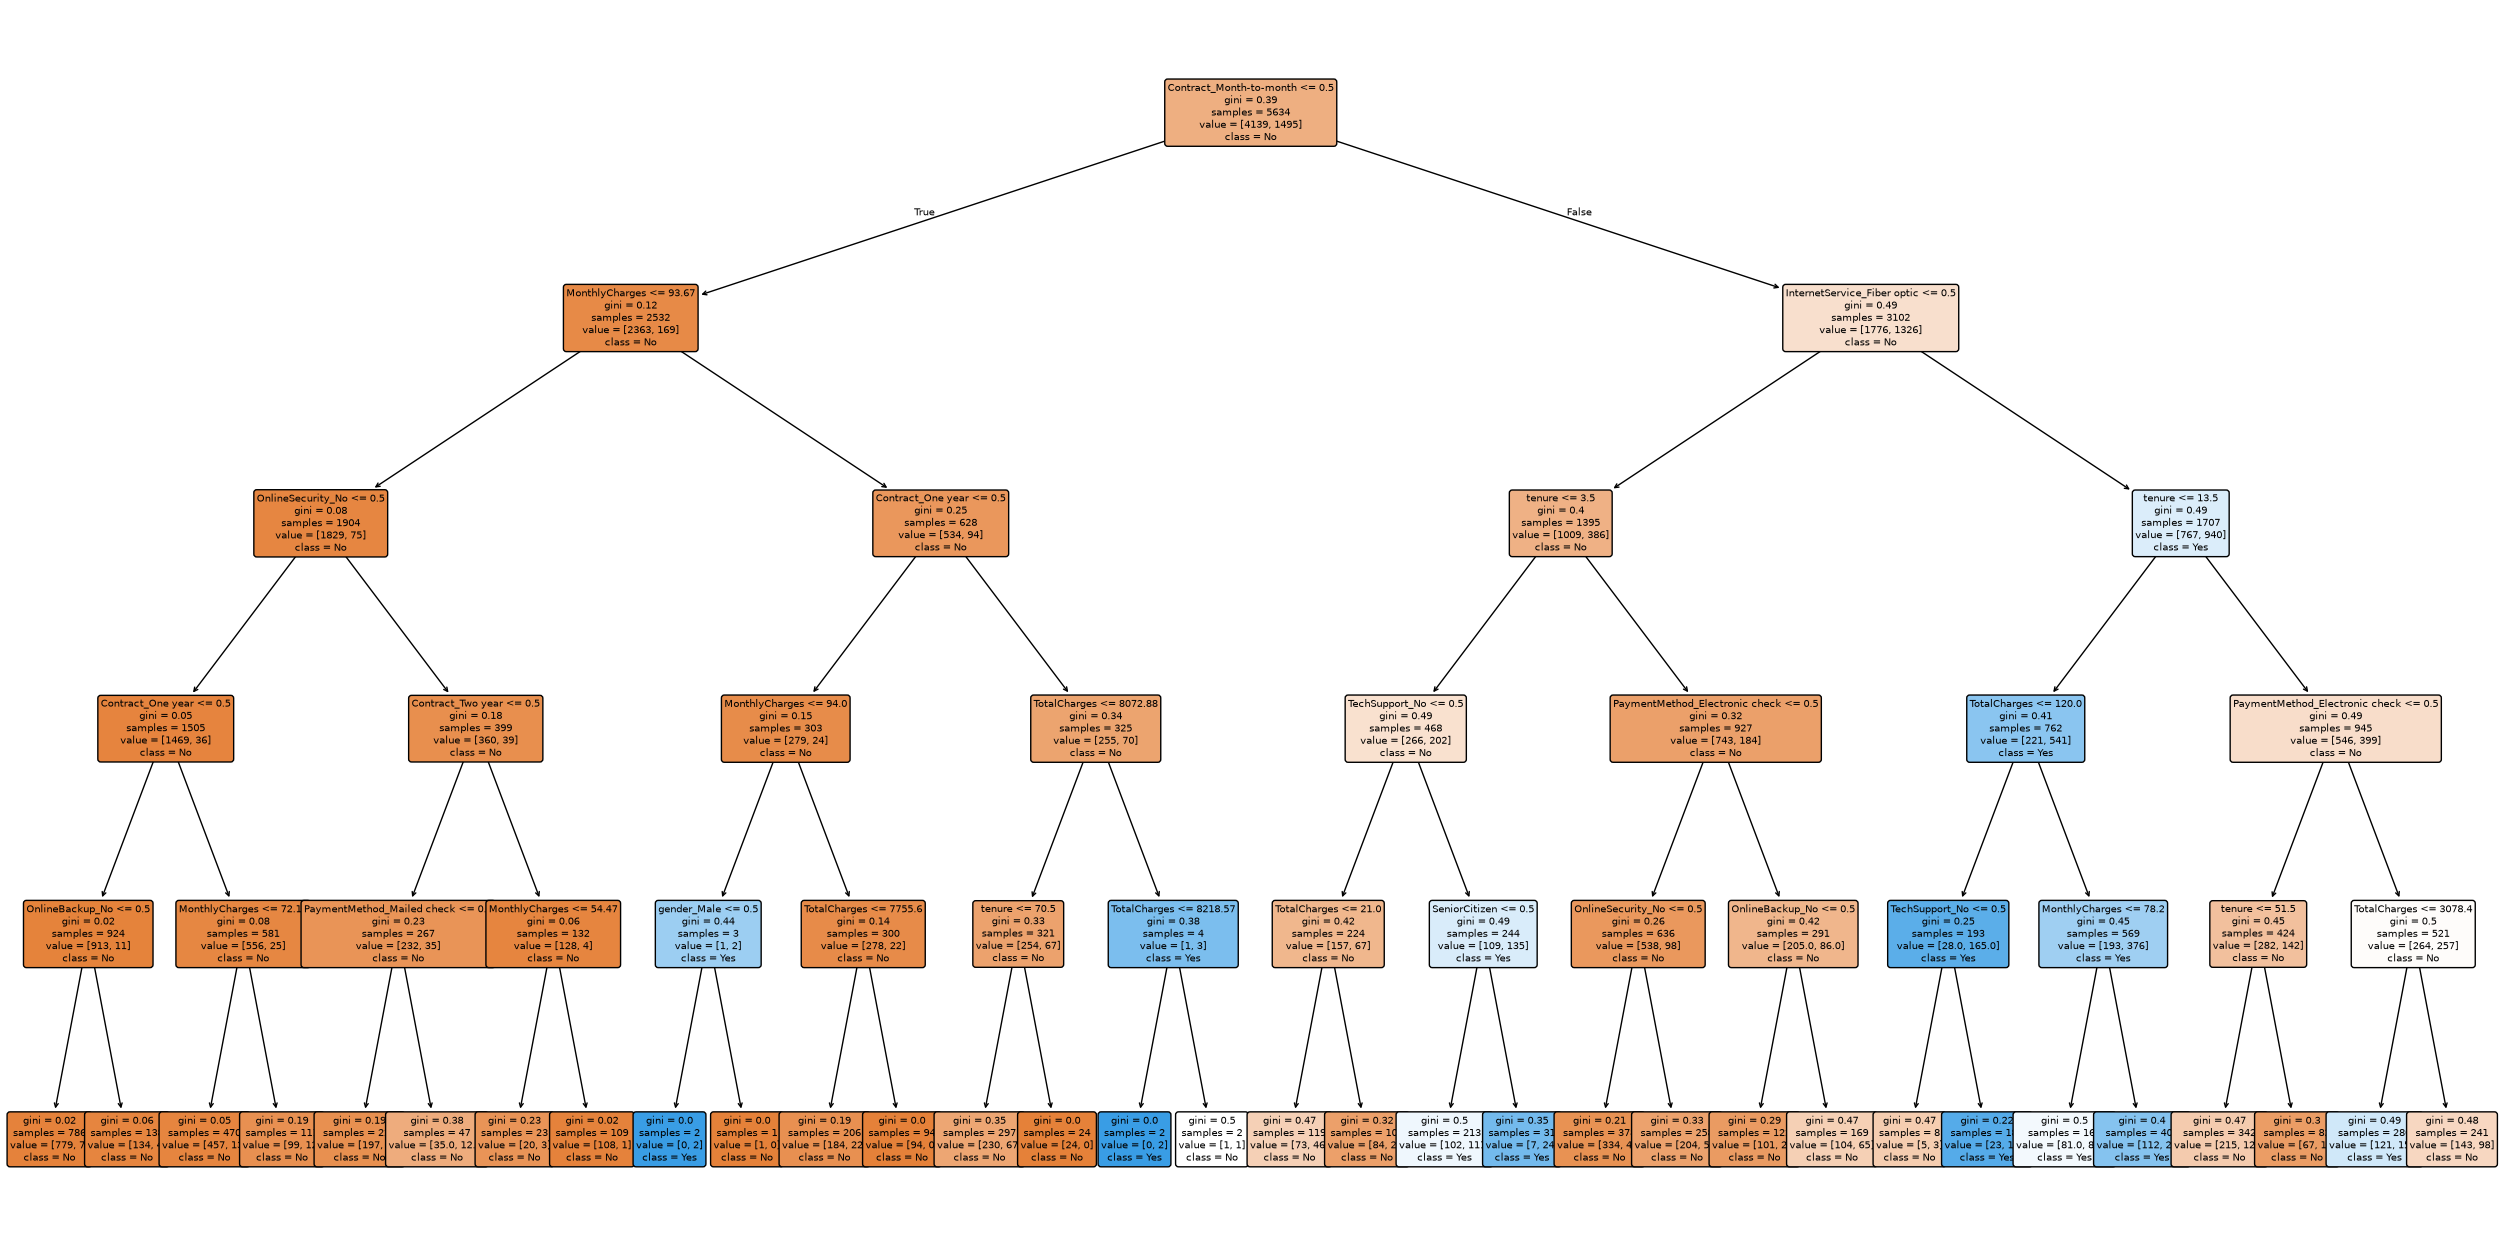

In [11]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

modelo_arbol = pipeline.named_steps["modelo"]
codificador = pipeline.named_steps["preprocesamiento"].named_transformers_["categoricas"].named_steps["codificar"]
nombres_variables = columnas_numericas + codificador.get_feature_names_out(columnas_categoricas).tolist()

plt.figure(figsize=(32, 16))
plot_tree(
    modelo_arbol, feature_names=nombres_variables, class_names=["No", "Yes"],
    filled=True, rounded=True, fontsize=7, precision=2
)
plt.show()

### Lectura de las reglas y criterio Gini

Cada nodo plantea una condición sobre una variable. Si se cumple, se sigue la rama izquierda; si no, la derecha. Las variables creadas por OneHotEncoder representan categorías con 0 o 1: una condición de 0.5 separa a quienes pertenecen a esa categoría de quienes no. En una hoja, la clase indicada es la predicción; samples muestra los registros de entrenamiento que llegaron allí y value presenta su distribución por clase. El color señala la clase predominante.

El índice Gini mide la mezcla de clases en un nodo. Un valor de 0 indica que todos los registros del nodo pertenecen a una sola clase. El árbol elige divisiones que reducen esta mezcla.

In [12]:
importancias = pd.Series(
    modelo_arbol.feature_importances_, index=nombres_variables
).sort_values(ascending=False)
display(importancias.head(10).to_frame("Importancia"))

,Importancia
Contract_Month-to-month,0.513973
InternetService_Fiber optic,0.163262
tenure,0.156717
TotalCharges,0.036499
MonthlyCharges,0.035922
PaymentMethod_Electronic check,0.027931
TechSupport_No,0.026824
Contract_One year,0.009218
OnlineBackup_No,0.009198
OnlineSecurity_No,0.008620


### Variables importantes

La tabla ordena las variables transformadas según su contribución a la reducción de impureza en este árbol. Una importancia alta indica que el árbol utilizó más esa variable para separar clases; no demuestra una relación causal.

### Resultados obtenidos en prueba

El árbol obtuvo **Accuracy = 0,7984**: clasificó correctamente 1125 de 1409 clientes de prueba. La **Precision = 0,6347** indica que, entre los clientes que predijo como abandono, el 63,47 % realmente abandonó. El **Recall = 0,5668** indica que detectó el 56,68 % de los abandonos reales; 162 de 374 quedaron sin detectar. El **F1 = 0,5989** resume el equilibrio entre Precision y Recall para la clase de abandono.

Las mayores importancias correspondieron a contrato mes a mes (0,5140), servicio de fibra óptica (0,1633) y antigüedad del cliente (0,1567). Estos valores describen las divisiones de este árbol y no establecen causas del abandono.